# This code is for running a PD controller to decorrelate one motoneuron from a pair and achieve a presumed flexible control

In [1]:
using Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot

include("creation_model.jl")
include("calculate_rates_with_timebase.jl")
include("filter_input.jl") 
include("run_sim.jl")
include("conv_spikes.jl") 


┌ Warning: Error requiring `MakieCore` from `Polynomials`
│   exception = (LoadError("/Users/nmt121/.julia/packages/Polynomials/6i39P/ext/PolynomialsMakieCoreExt.jl", 1, ArgumentError("Package Polynomials does not have MakieCore in its dependencies:\n- If you have Polynomials checked out for development and have\n  added MakieCore as a dependency but haven't updated your primary\n  environment's manifest file, try `Pkg.resolve()`.\n- Otherwise you may need to report an issue with Polynomials")), Union{Ptr{Nothing}, Base.InterpreterIP}[Ptr{Nothing} @0x000000010d060b1e, Ptr{Nothing} @0x000000010b3f09bf, Ptr{Nothing} @0x000000010b421a0c, Ptr{Nothing} @0x000000010b420e62, Ptr{Nothing} @0x000000010b420a65, Ptr{Nothing} @0x000000010b421104, Ptr{Nothing} @0x000000010b421c34, Ptr{Nothing} @0x00000001205c3d67, Ptr{Nothing} @0x000000010b3f09bf, Ptr{Nothing} @0x00000001204b428a, Ptr{Nothing} @0x00000001204b3d62, Ptr{Nothing} @0x000000010b3f09bf, Ptr{Nothing} @0x000000010b3fd259, Ptr{Nothing} @0x0

conv_spikes (generic function with 1 method)

## Functions for the control algorithm

In [2]:
function run_sim_onemn(MN_list,i,inh_input) #tuned for one MN
    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end

function conv_spikes_rates(array1,array2)
    window_samples = round(Int, 400 * 10^-3 * 20000) ; # 400 ms * 20 kHz  
    hanning_window = DSP.Windows.hanning(window_samples);
    hanning_window ./= sum(hanning_window);# Normalize the window so it sums to 1 (to maintain the same scale after convolution)

    smoothed_spike_array1 = conv(array1[1,:], hanning_window)/(1/20000)
    smoothed_spike_array2 = conv(array2[1,:], hanning_window)/(1/20000)

    # Because convolution extends the length of the array, let's truncate it to the original length
    len = size(array1,2);
    smoothed_spike_array1 = smoothed_spike_array1[1:len];
    smoothed_spike_array2 = smoothed_spike_array2[1:len];
    print("")

return smoothed_spike_array1, smoothed_spike_array2
end
   

conv_spikes_rates (generic function with 1 method)

## Init control algorithm

In [105]:
######################  S-TYPE ##########################
#########################################################
nr_s = 87

JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/VthCa_TA_6sept.jld2" VthCa_newTA


# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = ones(nr_s)*22.0
βm = ones(nr_s)*13.0

αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4

αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1

αq_S = ones(nr_s)*1.5
βq_S = LinRange(0.025,0.038,nr_s) 

αp_D = 0.008
βp_D = LinRange(0.014,0.016,nr_s) 

Vthca_S = VthCa_newTA
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

# at some point delete these things
γa=1.;
γh = ones(nr_s)*0.7#γn_new
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion


#reversal potentials
EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 

#maximun conductances
Ge=0.6; Gi=0.5 ; 

#initial voltages
Vd0 = 0.; 
Vs0 = 0.;

#refractory period
rp=5.0; 

const step = 0.05;
_int(num) = floor(Int, num);

#Pulse duration [mS]
pd=1; 

ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;


tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
pt_arr = zeros((nr_s, sim_time)); #storage
mt_arr = zeros((nr_s, sim_time)); #storage
ht_arr = zeros((nr_s, sim_time)); #storage
nt_arr = zeros((nr_s, sim_time)); #storage
qt_arr = zeros((nr_s, sim_time)); #storage

commoninput = tr; #needed for the run_sim() function


full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))
factor= 0.1 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length);

In [77]:
Vthca_S[35]

6.6648607748119995

In [80]:
Vthca_S[26]

0.732874058421304

#### Checking pair of MNs

In [116]:
# mn1=86; mn2=31
# inh_input1 = vcat(fill(factor*amplitude, Int(sim_length/2)), range(factor* amplitude, stop=factor* amplitude+values_inh[mn1]*amplitude, length=Int(sim_length/2)))
# inh_input2 = vcat(fill(factor*amplitude, Int(sim_length/2)), range(factor* amplitude, stop=factor* amplitude+values_inh[mn2]*amplitude, length=Int(sim_length/2)))
# #
# Plots.plot(inh_input1,width=3)
# Plots.plot!(inh_input2,width=3)

In [106]:
mn1=26; mn2=35
spike_arr_mn1, _ = run_sim_onemn(MN_list[mn1], mn1,inh_input)  
spike_arr_mn2, _ = run_sim_onemn(MN_list[mn2], mn2,inh_input)

([0 0 … 0 0], [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])

In [107]:
## NATALIA OF THE FUTURE DONT RUN THIS CODE TWICE BECAUSE YOU ARE MAKING A TRAJECTORY WITH LESS POINTS IN EACH ITERATION

smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  

v = 20
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
    start_idx = (i - 1) * v + 1
    end_idx = i * v
    new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
    new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg;

# Plots.plot(trajectory2_controlled[:,1],trajectory2_controlled[:,1])  # Controlled trajectory from neurons)


30000×2 Matrix{Float64}:
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 ⋮    
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0

In [10]:
# Plots.plot([1:30000],tr_new,grid=false,legend=false,linewidth=6,color= :blue)  # Controlled trajectory from neurons)
# Plots.plot!([1:30000],inh_input,grid=false,legend=false,linewidth=6,color= :orange)  # Controlled trajectory from neurons)

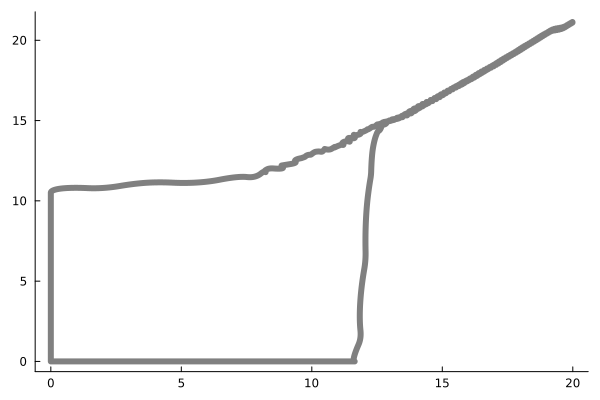

In [108]:
y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2]);
x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]));
trajectory1 = hcat(x_values, y_values) ; # This is the line that would make us achieve flexible control;

# Plots.plot(trajectory2_controlled[1:15000,1],trajectory2_controlled[1:15000,2])  # Controlled trajectory from neurons)
# Plots.plot(trajectory2_controlled[15000:30000,1],trajectory2_controlled[15000:30000,2])  # Controlled trajectory from neurons)
Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2],grid=false,legend=false,linewidth=6,color= :gray)  # Controlled trajectory from neurons)

# Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)


In [109]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/originaltrajectory_TA_MN26_35.jld2" force


## Control algorithm

In [94]:
###################### EXC ###################### (just controlling exc)
#################################################

# Control parameters
kp = Float32(4)  
kd = Float32(1)  
dt = Float32(0.1) 

# Motoneurons we are interested in comparing
mn1 = 26
mn2 = 35

# Init
previous_error= 0.0

tr_new = copy(tr)
# inh_input=fill(factor*amplitude, sim_length);
# inh_input2 = vcat(fill(factor*amplitude, Int(sim_length/2)), range(factor* amplitude, stop=factor* amplitude+values_inh[mn1]*amplitude, length=Int(sim_length/2)))


for  iteration in 1:20

    commoninput = tr_new  

    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_onemn(MN_list[mn1], mn1, inh_input) 
    spike_arr_mn2, _ = run_sim_onemn(MN_list[mn2], mn2, inh_input)  

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg #avg every 20 points
    

    # Trajectory we want to achieve (for flexibility)
    y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2])
    x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    trajectory1 = hcat(x_values, y_values)  

    # x_values = zeros(length(trajectory2_controlled[:, 2]))
    # y_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]));
    # trajectory1 = hcat(x_values, y_values) ; # This is the line that would make us achieve flexible control;
    

    start= Int(size(trajectory1, 1)/2) #we just want the controller to start half way

    flag=0
    
   
    for i in start:size(trajectory1, 1) 

        # computation of the euclidean error
        error1 = trajectory1[i, 1] - trajectory2_controlled[i, 1]
        error2 = trajectory1[i, 2] - trajectory2_controlled[i, 2]
        euclidean_error = sqrt(error1^2 + error2^2)

        # ERRORS FROM CONTROL OUTPUT
        # integral_error += euclidean_error * dt  
        derivative_error = (euclidean_error - previous_error) / dt
        control_output = kp * euclidean_error + kd * derivative_error #+ ki * integral_error 



        control_output *= 0.0001 #adaptative

        tr_new[i] += control_output  

        

        if tr_new[i]  >= 0.4 #it cant be greater than this 
            tr_new[i]=0.4
        end

        tr_new[15000]=amplitude


        if round(trajectory2_controlled[i, 1])==0
            tr_new[i] += control_output/2.6
        end

        previous_error = euclidean_error


    end

    
end

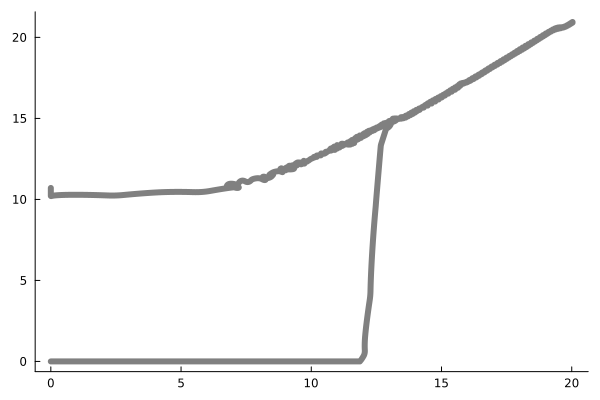

In [96]:
Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2],grid=false,legend=false,linewidth=6,color= :gray)  # Controlled trajectory from neurons)
# Plots.plot!(trajectory2_controlled[29900:30000,1],trajectory2_controlled[29900:30000,2],grid=false,legend=false,linewidth=6,color= :blue)  # Controlled trajectory from neurons)

# Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)

In [101]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/trajectory_controlled_TA_MN26_35.jld2" trajectory2_controlled
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/exc_TA_MN26_35.jld2" tr_new
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/inh_TA_MN26_35.jld2" inh_input
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/force_TA_MN26_35.jld2" force


In [101]:
submatrix = trajectory2_controlled[25000:30000, :]

# Count how many rows have column 1 == 0 and column 2 ≠ 0
count(x -> x[1] == 0 && x[2] != 0, eachrow(submatrix))


# # Initialize a counter for valid points
# counter = 0

# # Iterate through each pair of consecutive rows and check the conditions
# for i in 1:size(submatrix, 1)-1
#     if submatrix[i, 1] == 0 && submatrix[i, 2] != 0 && submatrix[i, 2] < submatrix[i+1, 2]
#         counter += 1
#     end
# end

# # Display the counter
# counter

19

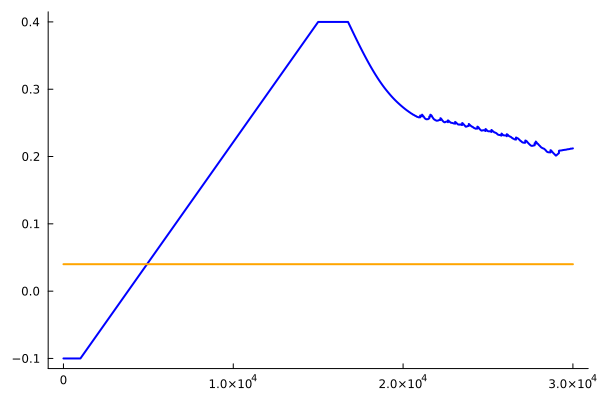

In [97]:
Plots.plot([1:30000],tr_new,grid=false,legend=false,linewidth=2,color= :blue)  # Controlled trajectory from neurons)
# Plots.plot!([25000:30000],tr_new[25000:30000],grid=false,legend=false,linewidth=2,color= :blue)  # Controlled trajectory from neurons)

Plots.plot!([1:30000],inh_input,grid=false,legend=false,linewidth=2,color= :orange)  # Controlled trajectory from neurons)

In [ ]:
Plots.scatter([2,6],[-59,23],grid=false, xlim=(=0.1,8))

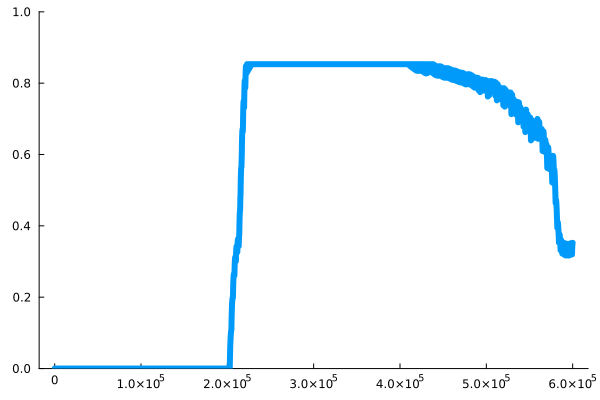

In [98]:
spike_array= vcat(spike_arr_mn1,spike_arr_mn2)
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);

Apeak_S= [Apeak_S[mn1], Apeak_S[mn2]]
tpeak_S= [tpeak_S[mn1], tpeak_S[mn2]]
tetanic_S= [tetanic_S[mn1], tetanic_S[mn2]]

T=0.05
twforce = zeros(size(spike_array))

for i in 1:size(spike_array, 1)
    firings = copy(spike_array) /0.05


    # filter coefficients
    a = [1, -2 * exp(-T / tpeak_S[i]), exp(-2 * T / tpeak_S[i])]
    b = [0, Apeak_S[i] * (T^2 / tpeak_S[i]) * exp(1 - T / tpeak_S[i])]

    twforce[i, :] = filt(b, a, firings[i, :])

    # Tetanic Limit
    twforce[i, twforce[i, :] .> tetanic_S[i]] .= tetanic_S[i]
end

force = sum(twforce, dims=1)# Sum forces from both neurons


Plots.plot([1:600000],force[1,:],ylim=[0,1],lw=6,grid=false,legend=false)


In [245]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/new_exc_flexibility_ONLYEXCchange_5Aug.jld2" tr_new
